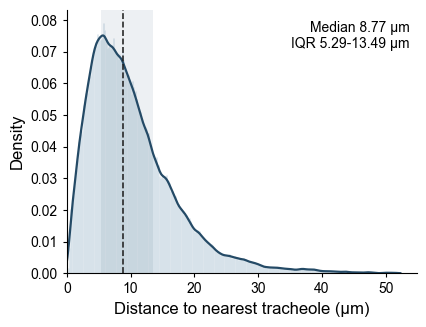

/Users/theang/Downloads/inter_tracheole_distance.svg


In [ ]:
"""
TASK 2 — Minimum distance between tracheoles.

Read the CATMAID skeleton IDs from the skeleton list and load the corresponding
tracheole skeleton nodes. Each skeleton is represented as connected parent-child
node pairs, where each child node is associated with its directly preceding parent
node. Each parent-child skeleton edge is resampled at 100 nm spacing. For every
resampled point, calculate the Euclidean distance to the nearest point belonging to
a distinct tracheole skeleton.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from tqdm import tqdm
import pymaid

downloads = Path.home() / "Downloads"
skel_csv = downloads / "catmaid_skeletons.csv"
node_csv = (downloads / "catmaid_nodes.csv")
svg = downloads / "inter_tracheole_dist.svg"

server = "https://spine.itanna.io/catmaid/fafb-edu/"
project = 4
api = "xxx"  # replace with your own CATMAID API token
workers = 4
mem_mb = 256
k0, kmax = 16, 256
nm_per_um = 1000
spacing_nm = 100.0

sheet = pd.read_csv(skel_csv)
skids = (pd.to_numeric(sheet["skeleton_id"], errors="coerce")
         .dropna().drop_duplicates().tolist())

def get_nodes():
    """Download and combine all skeleton nodes."""
    if node_csv.exists():
        n = pd.read_csv(node_csv)
    else:
        rows = []
        for sid in tqdm(skids, desc="CATMAID skeletons"):
            neuron = pymaid.get_neuron(int(sid),remote_instance=pymaid.CatmaidInstance(server,api_token=api, project_id=project),
                                       with_connectors=False)
            if not hasattr(neuron, "nodes"): neuron = list(neuron)[0]
            t = neuron.nodes[["node_id", "parent_id", "x", "y", "z"]].copy()
            t["skeleton_id"] = int(sid)
            t = t.rename(columns={"x": "x_nm", "y": "y_nm", "z": "z_nm"})
            rows.append(t)
        n = pd.concat(rows, ignore_index=True)
        node_csv.parent.mkdir(parents=True, exist_ok=True)
        n.to_csv(node_csv, index=False)

    n = n[["skeleton_id", "node_id", "parent_id", "x_nm", "y_nm", "z_nm"]].copy()
    n.columns = ["sid", "nid", "parent", "x", "y", "z"]
    return n[n["sid"].isin(skids)].reset_index(drop=True)

def resample(nodes):
    """Sample each skeleton edge at 100nm spacing."""
    pts = []
    for sid, g in nodes.groupby("sid"):
        xyz = g.set_index("nid")[["x", "y", "z"]]

        # Add root nodes once
        for _, r in g[g["parent"].isna()].iterrows():
            pts.append((sid, r["x"], r["y"], r["z"]))

        # Sample every parent-child edge
        for _, r in g.dropna(subset=["parent"]).iterrows():
            parent = int(r["parent"])
            if parent not in xyz.index:
                continue
            a = xyz.loc[parent].to_numpy(float)
            b = r[["x", "y", "z"]].to_numpy(float)
            length = np.linalg.norm(b - a)
            n = max(1, int(np.ceil(length / spacing_nm)))

            # Exclude the parent to avoid duplicate edge endpoints
            for t in np.linspace(0, 1, n + 1)[1:]:
                p = a + t * (b - a)
                pts.append((sid, *p))

    return pd.DataFrame(pts, columns=["sid", "x", "y", "z"])

def query(tree, xyz, sid, ids, k):
    """Find nearest different-skeleton candidates."""
    ok = np.zeros(len(ids), dtype=bool)
    dist = np.full(len(ids), np.nan)
    near = np.full(len(ids), -1, dtype=np.int64)
    # Limit each query block to control memory use
    step = max(1, min(len(ids), mem_mb * 1024**2 // (40 * k)))

    for a in range(0, len(ids), step):
        q = ids[a:a + step]
        dd, jj = tree.query(xyz[q], k=k, workers=workers)

        # Ignore neighbours from the same tracheole
        other = sid[jj] != sid[q, None]
        r = np.flatnonzero(other.any(axis=1))

        if len(r):
            c = other[r].argmax(axis=1)
            dst = a + r
            ok[dst] = True
            dist[dst] = dd[r, c]
            near[dst] = jj[r, c]

    return ok, dist, near

def fallback(xyz, sid, ids):
    """Exactly resolve nodes not found within kmax."""
    dist = np.empty(len(ids))
    near = np.empty(len(ids), dtype=np.int64)
    src_sid = sid[ids]

    # Process unresolved nodes by skeleton
    for s in np.unique(src_sid):
        r = np.flatnonzero(src_sid == s)
        # Search only points belonging to other tracheoles
        other = np.flatnonzero(sid != s)
        dd, jj = cKDTree(xyz[other]).query(xyz[ids[r]], k=1, workers=workers)
        dist[r] = dd
        near[r] = other[jj]

    return dist, near

def nearest_other(nodes):
    """Calculate one nearest-other-tracheole distance per node."""
    xyz = nodes[["x", "y", "z"]].to_numpy(dtype=float)
    sid = nodes["sid"].to_numpy(dtype=np.int64)

    # Build one global spatial index
    tree = cKDTree(xyz)
    dist = np.full(len(nodes), np.nan)
    near = np.full(len(nodes), -1, dtype=np.int64)

    # Initially, every node is unresolved
    left = np.arange(len(nodes))
    k = k0

    # Progressively increase neighbour count
    while len(left):
        ok, dd, jj = query(tree, xyz, sid, left, k)

        dist[left[ok]] = dd[ok]
        near[left[ok]] = jj[ok]
        left = left[~ok]

        if not len(left) or k == kmax:
            break

        k = min(k * 2, kmax)

    # Resolve any remaining nodes exactly
    if len(left):
        dist[left], near[left] = fallback(xyz, sid, left)

    # Confirm every result belongs to another skeleton
    assert np.all(near >= 0)
    assert np.all(sid != sid[near])

    return dist / nm_per_um

nodes = get_nodes()
nodes = resample(nodes)
d = nearest_other(nodes)
median = float(np.median(d))
q1, q3 = np.quantile(d, [0.25, 0.75])

plt.rcParams.update({"font.family": "Arial", "font.size": 11, "axes.labelsize": 12,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "axes.linewidth": 0.8,
                     "xtick.direction": "out", "ytick.direction": "out", "svg.fonttype": "none",})

fig, ax = plt.subplots(figsize=(4.4, 3.4))

bins = np.histogram_bin_edges(d, bins="fd")
ax.hist(d, bins=bins, density=True, color="#6F97B5",
        edgecolor="white", linewidth=0.45, alpha=0.72)

if len(np.unique(d)) > 1:
    x = np.linspace(0, d.max(), 500)
    kde = gaussian_kde(d)
    ax.plot(x, kde(x), color="#244A66", lw=1.6)

ax.axvspan(q1, q3, color="#244A66", alpha=0.08, lw=0)
ax.axvline(median, color="#202020", lw=1.15, ls="--")

ax.text(0.98, 0.96, f"Median {median:.2f} µm\nIQR {q1:.2f}-{q3:.2f} µm",
    transform=ax.transAxes, ha="right", va="top", fontsize=10)

ax.set_xlabel("Distance to nearest tracheole (µm)")
ax.set_ylabel("Density")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(length=3, width=0.8)
ax.margins(x=0)

fig.tight_layout()
fig.savefig(svg, format="svg", bbox_inches="tight")
plt.show()

print(svg)